# Final Test Evaluation and Poster-Ready Results

Model development was completed using only the training and validation subsets. The final candidate was selected from validation results before this evaluation. The previously untouched test subset is used once to estimate final performance; no model optimization, candidate replacement, threshold tuning, or additional training will be performed after the test results are observed.

This notebook contains evaluation and interpretability procedures only. It does not train a model and does not treat model predictions as clinical diagnoses.


## 1. Imports and Reproducibility

The random seed controls Python, NumPy, and PyTorch operations. Deterministic execution is requested where practical, and the available compute environment is recorded with the final evaluation.


In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
import torch.nn.functional as F
import torchvision
from torch import nn
from torch.utils.data import DataLoader, Dataset
import torchvision.transforms.functional as TF
from torchvision.models import EfficientNet_V2_S_Weights, efficientnet_v2_s
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for evaluation and sampling."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

CUDA_AVAILABLE = torch.cuda.is_available()
DEVICE = torch.device("cuda" if CUDA_AVAILABLE else "cpu")
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"CUDA runtime: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(
    f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB"
    if CUDA_AVAILABLE
    else "Total GPU memory: Not available"
)


PyTorch version: 2.13.0+cu132
torchvision version: 0.28.0+cu132
CUDA available: True
CUDA runtime: 13.2
Selected device: cuda
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths

The project root is resolved from the current working directory. Required inputs are checked before the test manifest or checkpoint is loaded, and all final outputs are written under `reports/`.


In [2]:
def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the frozen test manifest and selection report."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / "data" / "processed" / "test.csv").is_file()
            and (candidate / "reports" / "07_final_candidate_selection.csv").is_file()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing data/processed/test.csv "
        "and reports/07_final_candidate_selection.csv."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw" / "skin-diseases-image-dataset" / "IMG_CLASSES"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
POSTER_FIGURES_DIR = FIGURES_DIR / "poster"
MODELS_DIR = PROJECT_ROOT / "models"
PREDICTIONS_DIR = REPORTS_DIR / "predictions"

for directory in [REPORTS_DIR, FIGURES_DIR, POSTER_FIGURES_DIR, PREDICTIONS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

TEST_MANIFEST_PATH = PROCESSED_DIR / "test.csv"
FINAL_SELECTION_PATH = REPORTS_DIR / "07_final_candidate_selection.csv"

for required_path in [TEST_MANIFEST_PATH, FINAL_SELECTION_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Required input is missing: {required_path}")

print(f"Project root: {PROJECT_ROOT}")
print(f"Test manifest: {TEST_MANIFEST_PATH}")
print(f"Poster figure directory: {POSTER_FIGURES_DIR}")


Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Test manifest: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\processed\test.csv
Poster figure directory: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\figures\poster


## 3. Final Candidate Selection

The final checkpoint is determined exclusively from notebook 07 outputs. Test results do not participate in this decision.


In [3]:
candidate_selection = pd.read_csv(FINAL_SELECTION_PATH)
SELECTION_COLUMNS = {
    "candidate",
    "validation_accuracy",
    "validation_balanced_accuracy",
    "validation_macro_f1",
    "selected",
}
missing_selection_columns = SELECTION_COLUMNS - set(candidate_selection.columns)
if missing_selection_columns:
    raise ValueError(
        "The candidate-selection report is missing columns: "
        f"{sorted(missing_selection_columns)}"
    )

selected_mask = (
    candidate_selection["selected"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin({"true", "1", "yes"})
)
if selected_mask.sum() != 1:
    raise ValueError("Exactly one final candidate must be marked as selected.")

FINAL_CANDIDATE = str(candidate_selection.loc[selected_mask, "candidate"].iloc[0])
CANDIDATE_CONFIGURATION = {
    "efficientnetv2_s_optimized": {
        "checkpoint": MODELS_DIR / "efficientnetv2_s_optimized_best.pth",
        "validation_metrics": REPORTS_DIR / "07_efficientnetv2_optimized_validation_metrics.csv",
        "display_name": "Optimized EfficientNetV2-S",
    },
    "efficientnetv2_s_baseline": {
        "checkpoint": MODELS_DIR / "efficientnetv2_s_baseline_best.pth",
        "validation_metrics": REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv",
        "display_name": "EfficientNetV2-S Baseline",
    },
}
if FINAL_CANDIDATE not in CANDIDATE_CONFIGURATION:
    raise ValueError(f"Unsupported selected candidate: {FINAL_CANDIDATE}")

FINAL_CHECKPOINT_PATH = CANDIDATE_CONFIGURATION[FINAL_CANDIDATE]["checkpoint"]
SELECTED_VALIDATION_METRICS_PATH = CANDIDATE_CONFIGURATION[FINAL_CANDIDATE][
    "validation_metrics"
]
FINAL_MODEL_DISPLAY_NAME = CANDIDATE_CONFIGURATION[FINAL_CANDIDATE]["display_name"]

for required_path in [FINAL_CHECKPOINT_PATH, SELECTED_VALIDATION_METRICS_PATH]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Selected-model artifact is missing: {required_path}")

display(
    candidate_selection[
        [
            "candidate",
            "validation_accuracy",
            "validation_balanced_accuracy",
            "validation_macro_f1",
            "selected",
        ]
    ].style.format(
        {
            "validation_accuracy": "{:.4f}",
            "validation_balanced_accuracy": "{:.4f}",
            "validation_macro_f1": "{:.4f}",
        }
    )
)
print(f"Selected final model: {FINAL_MODEL_DISPLAY_NAME}")
print(f"Selected checkpoint: {FINAL_CHECKPOINT_PATH}")


,candidate,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,selected
0,efficientnetv2_s_baseline,0.8892,0.8327,0.8319,False
1,efficientnetv2_s_optimized,0.8950,0.8394,0.8391,True


Selected final model: Optimized EfficientNetV2-S
Selected checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_optimized_best.pth


## 4. Frozen Test Manifest

The test manifest is validated without modification. Structural checks cover required fields, label consistency, unique image references, optional group identifiers, split labels, and file existence.


In [4]:
test_manifest = pd.read_csv(TEST_MANIFEST_PATH)
REQUIRED_TEST_COLUMNS = {"relative_path", "class_id", "class_name"}
missing_test_columns = REQUIRED_TEST_COLUMNS - set(test_manifest.columns)
if missing_test_columns:
    raise ValueError(
        f"The test manifest is missing columns: {sorted(missing_test_columns)}"
    )
if test_manifest.empty:
    raise ValueError("The test manifest is empty.")
if test_manifest[list(REQUIRED_TEST_COLUMNS)].isna().any().any():
    raise ValueError("Required test-manifest fields contain missing values.")
if test_manifest["relative_path"].duplicated().any():
    duplicate_count = int(test_manifest["relative_path"].duplicated().sum())
    raise ValueError(f"The test manifest contains {duplicate_count} duplicate paths.")
if "group_id" in test_manifest.columns and test_manifest["group_id"].isna().any():
    raise ValueError("The test manifest contains missing group identifiers.")
if "split" in test_manifest.columns:
    observed_splits = set(test_manifest["split"].astype(str).str.lower())
    if observed_splits != {"test"}:
        raise ValueError(f"Unexpected split labels in the test manifest: {observed_splits}")

test_manifest["class_id"] = test_manifest["class_id"].astype(int)
missing_image_paths = [
    relative_path
    for relative_path in test_manifest["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_image_paths:
    preview = "\n".join(f"  - {path}" for path in missing_image_paths[:10])
    raise FileNotFoundError(
        f"The test manifest references {len(missing_image_paths)} missing images."
        f"\nFirst missing paths:\n{preview}"
    )

test_class_distribution = (
    test_manifest.groupby(["class_id", "class_name"])
    .size()
    .rename("test_images")
    .reset_index()
    .sort_values("class_id", ignore_index=True)
)
print(f"Total test images: {len(test_manifest):,}")
print(f"Number of classes: {test_manifest['class_id'].nunique()}")
display(test_class_distribution)


Total test images: 3,960
Number of classes: 10


,class_id,class_name,test_images
0,0,Eczema,230
1,1,Melanoma,470
2,2,Atopic Dermatitis,174
3,3,Basal Cell Carcinoma (BCC),496
4,4,Melanocytic Nevi (NV),1195
5,5,Benign Keratosis-like Lesions (BKL),309
6,6,Psoriasis / Lichen Planus / Related Diseases,291
7,7,Seborrheic Keratoses / Other Benign Tumors,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...,243
9,9,Warts / Molluscum / Other Viral Infections,279


## 5. Class Mapping and Checkpoint Metadata

Class identifiers and names are derived from the frozen manifest. The checkpoint mapping must match the manifest exactly before model reconstruction proceeds.


In [5]:
class_mapping_table = (
    test_manifest[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if (
    class_mapping_table["class_id"].duplicated().any()
    or class_mapping_table["class_name"].duplicated().any()
):
    raise ValueError("The test class mapping is not one-to-one.")
expected_class_ids = list(range(len(class_mapping_table)))
if class_mapping_table["class_id"].tolist() != expected_class_ids:
    raise ValueError("Test class IDs must be contiguous from zero.")

CLASS_ID_TO_NAME = {
    int(row.class_id): str(row.class_name)
    for row in class_mapping_table.itertuples(index=False)
}
NUM_CLASSES = len(CLASS_ID_TO_NAME)

checkpoint = torch.load(
    FINAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)
if "model_state_dict" not in checkpoint:
    raise KeyError("The selected checkpoint does not contain model_state_dict.")
if "class_mapping" not in checkpoint:
    raise KeyError("The selected checkpoint does not contain class_mapping.")

checkpoint_class_mapping = {
    int(class_id): str(class_name)
    for class_id, class_name in checkpoint["class_mapping"].items()
}
if checkpoint_class_mapping != CLASS_ID_TO_NAME:
    raise ValueError(
        "The checkpoint class mapping differs from the frozen test-manifest mapping."
    )

display(class_mapping_table)
print("Checkpoint and test-manifest class mappings match exactly.")


,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Checkpoint and test-manifest class mappings match exactly.


## 6. Final Model Reconstruction

The selected EfficientNetV2-S architecture is reconstructed from checkpoint metadata. The optimized checkpoint uses its saved classifier dropout; the baseline retains the baseline classifier configuration. State-dictionary loading is strict, all parameters remain unchanged, and the model is placed in evaluation mode.


In [6]:
training_configuration = checkpoint.get("training_configuration", {})
IMAGE_SIZE = int(
    checkpoint.get(
        "image_size",
        training_configuration.get("image_size", 384),
    )
)
if IMAGE_SIZE != 384:
    raise ValueError(
        f"The selected checkpoint specifies an unexpected input size: {IMAGE_SIZE}."
    )

model = efficientnet_v2_s(weights=None)
dropout_layers = [
    module for module in model.classifier if isinstance(module, nn.Dropout)
]
if len(dropout_layers) != 1:
    raise ValueError("Expected exactly one classifier dropout layer.")

if FINAL_CANDIDATE == "efficientnetv2_s_optimized":
    if "dropout" not in checkpoint and "classifier_dropout" not in training_configuration:
        raise KeyError("The optimized checkpoint does not record classifier dropout.")
    CLASSIFIER_DROPOUT = float(
        checkpoint.get(
            "dropout",
            training_configuration["classifier_dropout"],
        )
    )
else:
    CLASSIFIER_DROPOUT = float(
        training_configuration.get("classifier_dropout", dropout_layers[0].p)
    )

dropout_layers[0].p = CLASSIFIER_DROPOUT
classifier_input_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(classifier_input_features, NUM_CLASSES)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model = model.to(DEVICE)
model.eval()

# Gradients are not needed for parameters during evaluation or Grad-CAM.
for parameter in model.parameters():
    parameter.requires_grad_(False)

checkpoint_architecture = checkpoint.get(
    "architecture",
    training_configuration.get("architecture", "EfficientNetV2-S"),
)
checkpoint_epoch = checkpoint.get("epoch", "Not recorded")
checkpoint_validation_macro_f1 = checkpoint.get(
    "best_validation_macro_f1",
    "Not recorded",
)

print(f"Candidate: {FINAL_CANDIDATE}")
print(f"Architecture: {checkpoint_architecture}")
print(f"Input resolution: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Classifier dropout: {CLASSIFIER_DROPOUT:.2f}")
print(f"Checkpoint epoch: {checkpoint_epoch}")
if isinstance(checkpoint_validation_macro_f1, (float, int)):
    print(
        "Checkpoint validation macro F1: "
        f"{float(checkpoint_validation_macro_f1):.4f}"
    )
else:
    print(f"Checkpoint validation macro F1: {checkpoint_validation_macro_f1}")


Candidate: efficientnetv2_s_optimized
Architecture: EfficientNetV2-S Optimized
Input resolution: 384 x 384
Classifier dropout: 0.30
Checkpoint epoch: 23
Checkpoint validation macro F1: 0.8391


## 7. Deterministic Test Preprocessing

Test images use the same deterministic EfficientNetV2-S preprocessing as validation: resize, center crop, tensor conversion, and ImageNet normalization from the torchvision weights configuration. No augmentation, random crop, test-time augmentation, or test-dependent tuning is applied.


In [7]:
PRETRAINED_WEIGHTS = EfficientNet_V2_S_Weights.DEFAULT
test_transform = PRETRAINED_WEIGHTS.transforms()
IMAGENET_MEAN = list(test_transform.mean)
IMAGENET_STD = list(test_transform.std)

crop_size = tuple(test_transform.crop_size)
if crop_size not in {(IMAGE_SIZE,), (IMAGE_SIZE, IMAGE_SIZE)}:
    raise ValueError(
        "The deterministic validation transform does not match the checkpoint "
        f"resolution: crop_size={crop_size}, image_size={IMAGE_SIZE}."
    )

print(f"Weights preprocessing: {PRETRAINED_WEIGHTS.name}")
print(f"Resize size: {test_transform.resize_size}")
print(f"Crop size: {test_transform.crop_size}")
print(f"Normalization mean: {IMAGENET_MEAN}")
print(f"Normalization standard deviation: {IMAGENET_STD}")
print("Random test augmentation: False")
print("Test-time augmentation: False")


Weights preprocessing: IMAGENET1K_V1
Resize size: [384]
Crop size: [384]
Normalization mean: [0.485, 0.456, 0.406]
Normalization standard deviation: [0.229, 0.224, 0.225]
Random test augmentation: False
Test-time augmentation: False


## 8. Test Dataset and DataLoader

Images are opened from the manifest paths, corrected for EXIF orientation, converted to RGB, and returned with their class identifiers and relative paths. Manifest order is preserved with `shuffle=False`.


In [8]:
class SkinDiseaseDataset(Dataset):
    """Load images, labels, and paths from an immutable manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), str(row["relative_path"])


test_dataset = SkinDiseaseDataset(
    test_manifest,
    PROJECT_ROOT,
    transform=test_transform,
)
BATCH_SIZE = int(training_configuration.get("batch_size", 8))
if BATCH_SIZE > 8:
    BATCH_SIZE = 8
NUM_WORKERS = 0
PIN_MEMORY = CUDA_AVAILABLE

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=False,
)

print(f"Test images: {len(test_dataset):,}")
print(f"Test batches: {len(test_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")


Test images: 3,960
Test batches: 495
Batch size: 8
DataLoader workers: 0
Pinned memory: True


## 9. One-Time Final Test Inference

This is the only full test-set inference pass. It uses `torch.inference_mode()` and CUDA automatic mixed precision when available. Re-running the cell in the same kernel is blocked to preserve the one-time evaluation protocol. The saved table contains the hard prediction, confidence, correctness indicator, and every class probability for each image.

The resulting test metrics must not be used to change the model, hyperparameters, augmentation, loss weighting, architecture, checkpoint, or decision thresholds. Model development is finished once these results are calculated.


In [9]:
if globals().get("FINAL_TEST_INFERENCE_COMPLETE", False):
    raise RuntimeError(
        "Final test inference has already been completed in this kernel. "
        "Do not repeat test evaluation."
    )

AMP_ENABLED = DEVICE.type == "cuda"


@torch.inference_mode()
def run_final_test_inference(model, loader, device) -> dict:
    """Run the single ordered test pass and return CPU prediction arrays."""
    model.eval()
    targets = []
    predictions = []
    confidences = []
    probability_batches = []
    relative_paths = []

    progress = tqdm(loader, desc="Final test inference", unit="batch")
    for images, labels, paths in progress:
        try:
            images = images.to(device, non_blocking=True)
            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory during final inference. Restart the "
                "kernel, free GPU memory, and rerun the notebook once from the "
                "beginning; do not change the model or preprocessing."
            ) from error

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        targets.extend(labels.numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        probability_batches.append(probabilities.cpu().numpy())
        relative_paths.extend(paths)

    return {
        "targets": np.asarray(targets, dtype=np.int64),
        "predictions": np.asarray(predictions, dtype=np.int64),
        "confidences": np.asarray(confidences, dtype=np.float32),
        "probabilities": np.concatenate(probability_batches, axis=0),
        "relative_paths": list(relative_paths),
    }


final_test_output = run_final_test_inference(model, test_loader, DEVICE)
expected_test_paths = test_manifest["relative_path"].astype(str).tolist()
if final_test_output["relative_paths"] != expected_test_paths:
    raise ValueError("Test prediction order differs from the frozen manifest order.")
if final_test_output["probabilities"].shape != (len(test_manifest), NUM_CLASSES):
    raise ValueError("The probability matrix has an unexpected shape.")

test_predictions = pd.DataFrame(
    {
        "relative_path": final_test_output["relative_paths"],
        "true_class_id": final_test_output["targets"],
        "true_class": [
            CLASS_ID_TO_NAME[int(class_id)]
            for class_id in final_test_output["targets"]
        ],
        "predicted_class_id": final_test_output["predictions"],
        "predicted_class": [
            CLASS_ID_TO_NAME[int(class_id)]
            for class_id in final_test_output["predictions"]
        ],
        "confidence": final_test_output["confidences"],
        "correct": final_test_output["targets"]
        == final_test_output["predictions"],
    }
)
for class_id in range(NUM_CLASSES):
    test_predictions[f"prob_class_{class_id}"] = final_test_output[
        "probabilities"
    ][:, class_id]

TEST_PREDICTIONS_PATH = (
    PREDICTIONS_DIR / "08_final_test_predictions.csv"
)
test_predictions.to_csv(TEST_PREDICTIONS_PATH, index=False, encoding="utf-8")
FINAL_TEST_INFERENCE_COMPLETE = True

print(f"Saved predictions: {TEST_PREDICTIONS_PATH}")
print(f"Prediction rows: {len(test_predictions):,}")
print("Final test inference complete: True")


Final test inference:   0%|          | 0/495 [00:00<?, ?batch/s]

Saved predictions: C:\Projekt konferencyjny Turcja\skin-disease-classification\reports\predictions\08_final_test_predictions.csv
Prediction rows: 3,960
Final test inference complete: True


## 10. Final Test Metrics

Aggregate and class-level metrics are calculated from the one-time predictions. Macro metrics weight classes equally, while weighted F1 accounts for test support. Undefined class-specific quantities use `zero_division=0`.


In [10]:
test_targets = final_test_output["targets"]
test_predicted = final_test_output["predictions"]
class_ids = np.arange(NUM_CLASSES, dtype=int)

test_metric_values = {
    "accuracy": accuracy_score(test_targets, test_predicted),
    "balanced_accuracy": balanced_accuracy_score(test_targets, test_predicted),
    "macro_f1": f1_score(
        test_targets, test_predicted, average="macro", zero_division=0
    ),
    "macro_precision": precision_score(
        test_targets, test_predicted, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        test_targets, test_predicted, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        test_targets, test_predicted, average="weighted", zero_division=0
    ),
}
test_metrics = pd.DataFrame(
    {"metric": list(test_metric_values), "value": list(test_metric_values.values())}
)

per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        test_targets,
        test_predicted,
        labels=class_ids,
        zero_division=0,
    )
)
test_per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)

test_metrics.to_csv(
    REPORTS_DIR / "08_final_test_metrics.csv", index=False, encoding="utf-8"
)
test_per_class_metrics.to_csv(
    REPORTS_DIR / "08_final_test_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

display(test_metrics.style.format({"value": "{:.4f}"}))
display(
    test_per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)


,metric,value
0,accuracy,0.8896
1,balanced_accuracy,0.8378
2,macro_f1,0.8353
3,macro_precision,0.8345
4,macro_recall,0.8378
5,weighted_f1,0.8900


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.6939,0.7391,0.7158,230
1,1,Melanoma,0.9812,0.9979,0.9895,470
2,2,Atopic Dermatitis,0.6170,0.6667,0.6409,174
3,3,Basal Cell Carcinoma (BCC),0.9480,0.9556,0.9518,496
4,4,Melanocytic Nevi (NV),0.9856,0.9749,0.9802,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.9094,0.9094,0.9094,309
6,6,Psoriasis / Lichen Planus / Related Diseases,0.8048,0.6942,0.7454,291
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8885,0.8462,0.8668,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.7417,0.8272,0.7821,243
9,9,Warts / Molluscum / Other Viral Infections,0.7754,0.7670,0.7712,279


## 11. Test Confusion Matrices

The raw matrix reports image counts. Row normalization reports the prediction distribution within each true class and therefore highlights class-conditional error patterns.


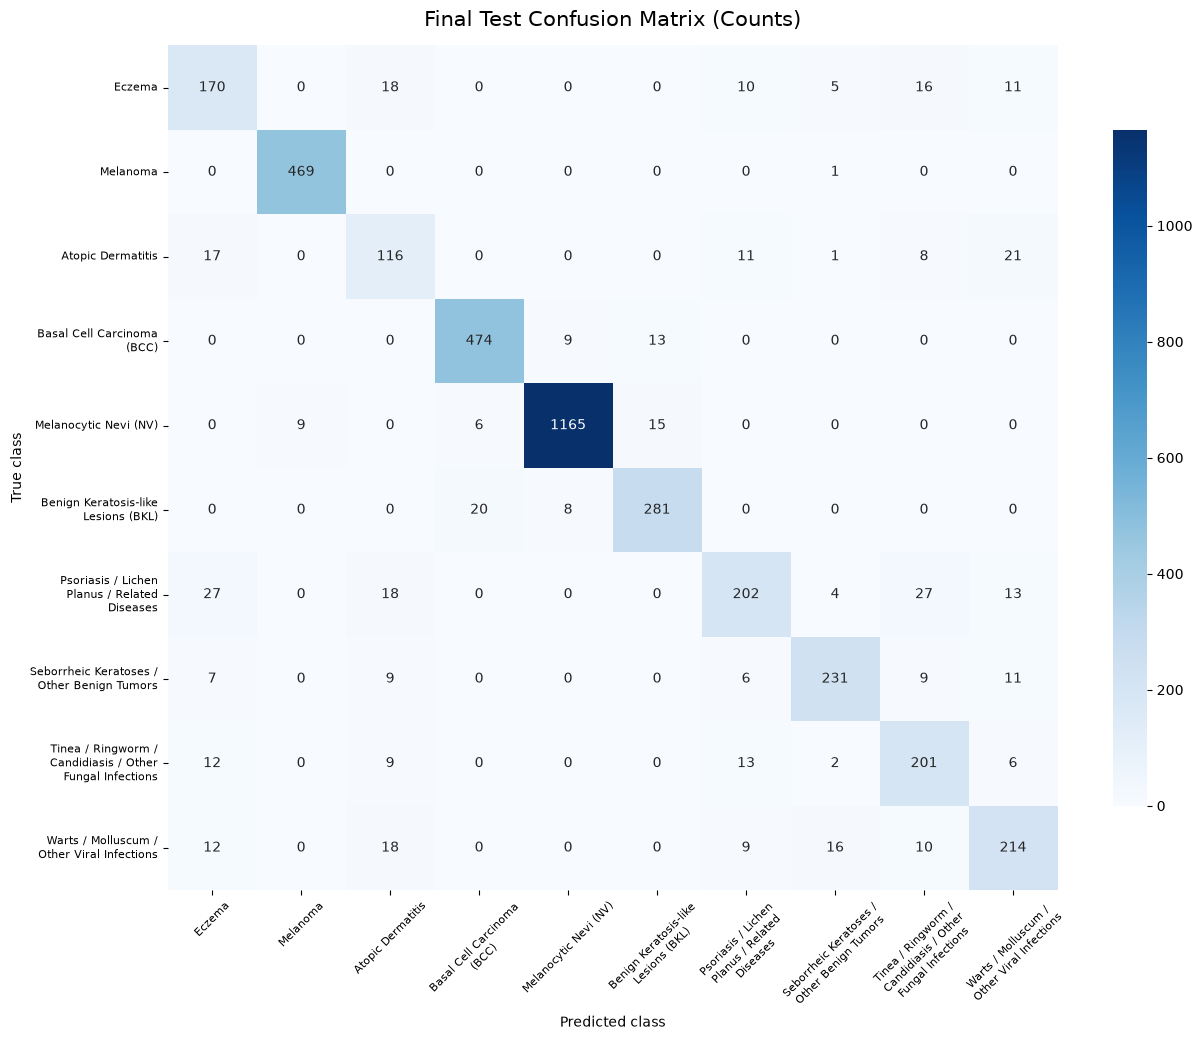

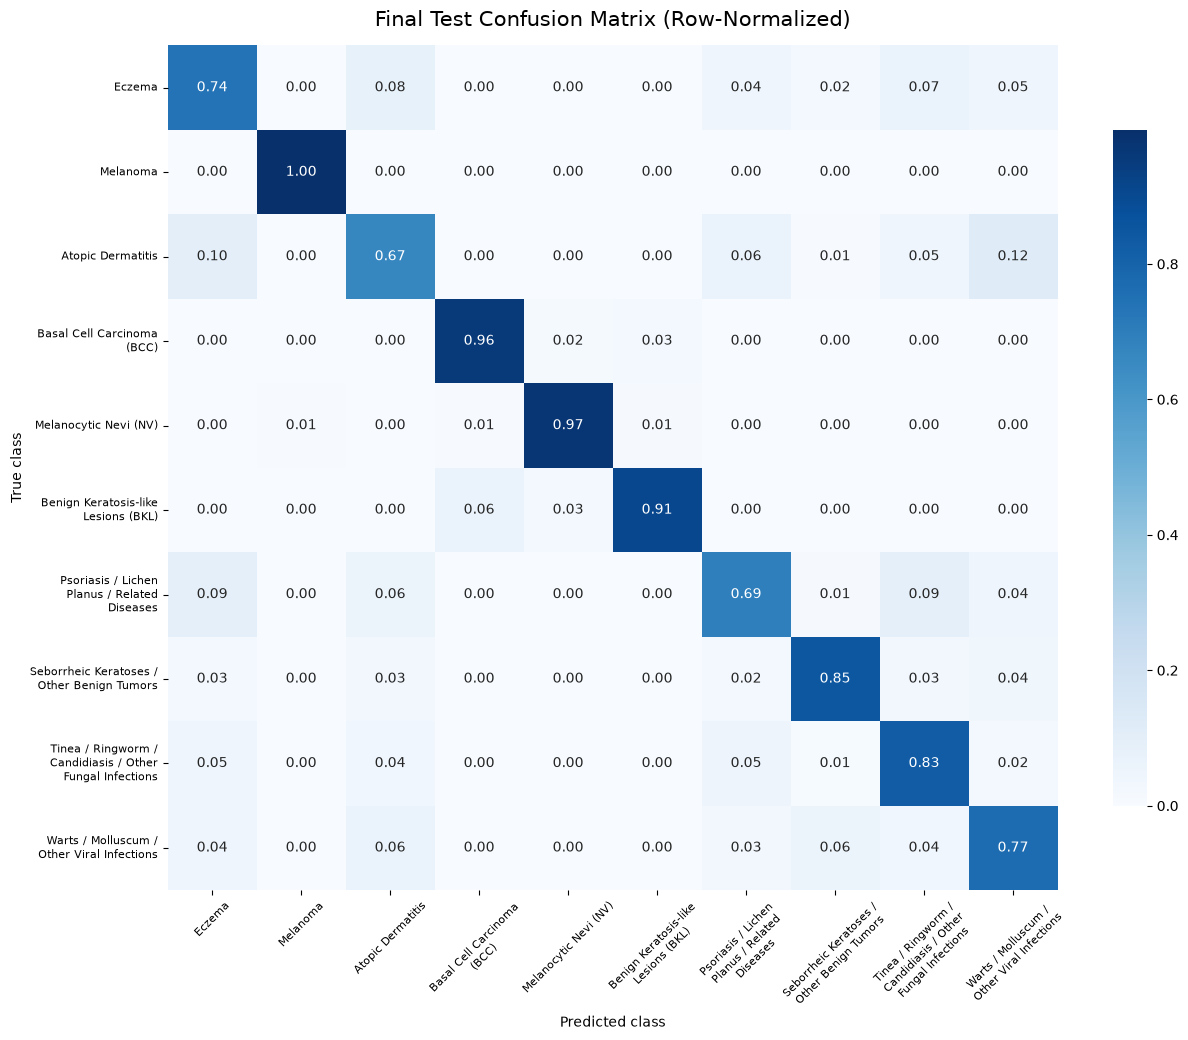

In [11]:
raw_confusion_matrix = confusion_matrix(
    test_targets,
    test_predicted,
    labels=class_ids,
)
normalized_confusion_matrix = confusion_matrix(
    test_targets,
    test_predicted,
    labels=class_ids,
    normalize="true",
)
analytical_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24)
    for class_id in class_ids
]


def save_analytical_confusion_matrix(
    matrix: np.ndarray,
    annotation_format: str,
    title: str,
    output_path: Path,
) -> None:
    """Save a high-resolution analytical confusion matrix."""
    fig, ax = plt.subplots(figsize=(13, 10.5))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=annotation_format,
        cmap="Blues",
        xticklabels=analytical_labels,
        yticklabels=analytical_labels,
        cbar_kws={"shrink": 0.8},
        ax=ax,
    )
    ax.set_title(title, fontsize=15, pad=14)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


save_analytical_confusion_matrix(
    raw_confusion_matrix,
    "d",
    "Final Test Confusion Matrix (Counts)",
    FIGURES_DIR / "08_final_test_confusion_matrix.png",
)
save_analytical_confusion_matrix(
    normalized_confusion_matrix,
    ".2f",
    "Final Test Confusion Matrix (Row-Normalized)",
    FIGURES_DIR / "08_final_test_confusion_matrix_normalized.png",
)


## 12. Validation-to-Test Comparison

Validation metrics for the preselected candidate are loaded from the corresponding report. Differences are defined as test minus validation. These paired descriptive values do not establish statistical significance.


In [12]:
selected_validation_metrics = pd.read_csv(SELECTED_VALIDATION_METRICS_PATH)
if not {"metric", "value"}.issubset(selected_validation_metrics.columns):
    raise ValueError("The selected validation report must contain metric and value.")
if selected_validation_metrics["metric"].duplicated().any():
    raise ValueError("The selected validation report contains duplicate metrics.")

validation_metric_values = selected_validation_metrics.set_index("metric")["value"]
COMPARISON_METRICS = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "weighted_f1",
]
missing_validation_metrics = set(COMPARISON_METRICS) - set(
    validation_metric_values.index
)
if missing_validation_metrics:
    raise ValueError(
        "The selected validation report is missing metrics: "
        f"{sorted(missing_validation_metrics)}"
    )

validation_vs_test = pd.DataFrame(
    {
        "metric": COMPARISON_METRICS,
        "validation": [
            float(validation_metric_values[metric])
            for metric in COMPARISON_METRICS
        ],
        "test": [test_metric_values[metric] for metric in COMPARISON_METRICS],
    }
)
validation_vs_test["difference"] = (
    validation_vs_test["test"] - validation_vs_test["validation"]
)
validation_vs_test.to_csv(
    REPORTS_DIR / "08_validation_vs_test_metrics.csv",
    index=False,
    encoding="utf-8",
)
display(
    validation_vs_test.style.format(
        {"validation": "{:.4f}", "test": "{:.4f}", "difference": "{:+.4f}"}
    )
)


,metric,validation,test,difference
0,accuracy,0.8950,0.8896,-0.0053
1,balanced_accuracy,0.8394,0.8378,-0.0016
2,macro_f1,0.8391,0.8353,-0.0038
3,macro_precision,0.8399,0.8345,-0.0053
4,macro_recall,0.8394,0.8378,-0.0016
5,weighted_f1,0.8951,0.8900,-0.0051


## 13. Test Error Analysis

Class-level extrema and directed confusion counts describe observed test behavior. They do not provide causal or clinical explanations for errors.


In [13]:
highest_recall_row = test_per_class_metrics.loc[
    test_per_class_metrics["recall"].idxmax()
]
lowest_recall_row = test_per_class_metrics.loc[
    test_per_class_metrics["recall"].idxmin()
]
highest_f1_row = test_per_class_metrics.loc[
    test_per_class_metrics["f1_score"].idxmax()
]
lowest_f1_row = test_per_class_metrics.loc[
    test_per_class_metrics["f1_score"].idxmin()
]

confusion_pair_records = []
for true_class_id in class_ids:
    true_support = raw_confusion_matrix[true_class_id].sum()
    for predicted_class_id in class_ids:
        if true_class_id == predicted_class_id:
            continue
        image_count = int(raw_confusion_matrix[true_class_id, predicted_class_id])
        if image_count == 0:
            continue
        confusion_pair_records.append(
            {
                "true_class_id": int(true_class_id),
                "true_class": CLASS_ID_TO_NAME[int(true_class_id)],
                "predicted_class_id": int(predicted_class_id),
                "predicted_class": CLASS_ID_TO_NAME[int(predicted_class_id)],
                "image_count": image_count,
                "proportion_of_true_class": image_count / true_support,
            }
        )

CONFUSION_PAIR_COLUMNS = [
    "true_class_id",
    "true_class",
    "predicted_class_id",
    "predicted_class",
    "image_count",
    "proportion_of_true_class",
]
test_confusion_pairs = (
    pd.DataFrame(confusion_pair_records, columns=CONFUSION_PAIR_COLUMNS)
    .sort_values(
        ["image_count", "proportion_of_true_class", "true_class_id"],
        ascending=[False, False, True],
        ignore_index=True,
    )
    .head(10)
)
test_confusion_pairs.to_csv(
    REPORTS_DIR / "08_test_confusion_pairs.csv",
    index=False,
    encoding="utf-8",
)

most_common_confusion = (
    test_confusion_pairs.iloc[0] if not test_confusion_pairs.empty else None
)
print(
    f"Highest-recall class: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest-recall class: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest-F1 class: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest-F1 class: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
if most_common_confusion is not None:
    print(
        "The model most frequently confused "
        f"{most_common_confusion['true_class']} with "
        f"{most_common_confusion['predicted_class']} "
        f"({int(most_common_confusion['image_count'])} images)."
    )
display(
    test_confusion_pairs.style.format(
        {"proportion_of_true_class": "{:.2%}"}
    )
)


Highest-recall class: Melanoma (0.9979)
Lowest-recall class: Atopic Dermatitis (0.6667)
Highest-F1 class: Melanoma (0.9895)
Lowest-F1 class: Atopic Dermatitis (0.6409)
The model most frequently confused Psoriasis / Lichen Planus / Related Diseases with Eczema (27 images).


,true_class_id,true_class,predicted_class_id,predicted_class,image_count,proportion_of_true_class
0,6,Psoriasis / Lichen Planus / Related Diseases,0,Eczema,27,9.28%
1,6,Psoriasis / Lichen Planus / Related Diseases,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,27,9.28%
2,2,Atopic Dermatitis,9,Warts / Molluscum / Other Viral Infections,21,12.07%
3,5,Benign Keratosis-like Lesions (BKL),3,Basal Cell Carcinoma (BCC),20,6.47%
4,0,Eczema,2,Atopic Dermatitis,18,7.83%
5,9,Warts / Molluscum / Other Viral Infections,2,Atopic Dermatitis,18,6.45%
6,6,Psoriasis / Lichen Planus / Related Diseases,2,Atopic Dermatitis,18,6.19%
7,2,Atopic Dermatitis,0,Eczema,17,9.77%
8,0,Eczema,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,16,6.96%
9,9,Warts / Molluscum / Other Viral Infections,7,Seborrheic Keratoses / Other Benign Tumors,16,5.73%


## 14. Test Confidence Analysis

Maximum softmax outputs are summarized separately for correct and incorrect predictions. They are model scores and must not be interpreted as calibrated medical probabilities.


In [14]:
correct_confidence = test_predictions.loc[
    test_predictions["correct"], "confidence"
]
incorrect_confidence = test_predictions.loc[
    ~test_predictions["correct"], "confidence"
]

confidence_summary_values = {
    "mean_confidence_correct": correct_confidence.mean(),
    "mean_confidence_incorrect": incorrect_confidence.mean(),
    "median_confidence_correct": correct_confidence.median(),
    "median_confidence_incorrect": incorrect_confidence.median(),
    "incorrect_confidence_ge_0.90": int((incorrect_confidence >= 0.90).sum()),
    "incorrect_confidence_ge_0.95": int((incorrect_confidence >= 0.95).sum()),
    "incorrect_confidence_ge_0.99": int((incorrect_confidence >= 0.99).sum()),
}
test_confidence_summary = pd.DataFrame(
    {
        "statistic": list(confidence_summary_values),
        "value": list(confidence_summary_values.values()),
    }
)
test_confidence_summary.to_csv(
    REPORTS_DIR / "08_test_confidence_summary.csv",
    index=False,
    encoding="utf-8",
)
display(test_confidence_summary.style.format({"value": "{:.4f}"}))
print("Softmax confidence is not a calibrated medical probability.")


,statistic,value
0,mean_confidence_correct,0.9257
1,mean_confidence_incorrect,0.7402
2,median_confidence_correct,0.9485
3,median_confidence_incorrect,0.7992
4,incorrect_confidence_ge_0.90,130.0000
5,incorrect_confidence_ge_0.95,36.0000
6,incorrect_confidence_ge_0.99,0.0000


Softmax confidence is not a calibrated medical probability.


## 15. Selected Prediction Examples

Four highest-confidence correct predictions and four highest-confidence errors are displayed in a deterministic order. These examples illustrate model outputs only and are not clinical interpretations.


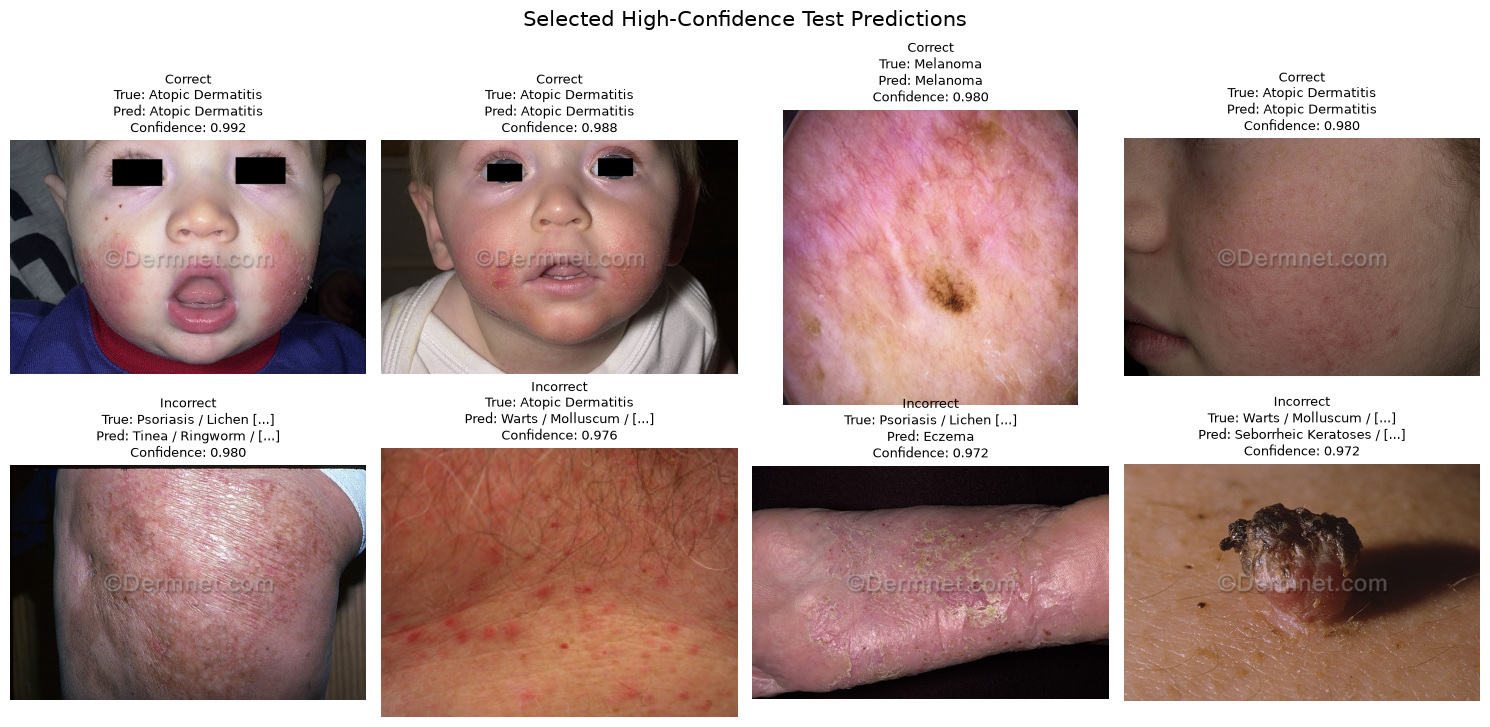

In [15]:
def load_display_image(relative_path: str) -> Image.Image:
    """Load an EXIF-corrected RGB image for visualization."""
    with Image.open(PROJECT_ROOT / relative_path) as image:
        return ImageOps.exif_transpose(image).convert("RGB").copy()


high_confidence_correct = (
    test_predictions.loc[test_predictions["correct"]]
    .sort_values(["confidence", "relative_path"], ascending=[False, True])
    .head(4)
)
high_confidence_incorrect = (
    test_predictions.loc[~test_predictions["correct"]]
    .sort_values(["confidence", "relative_path"], ascending=[False, True])
    .head(4)
)
selected_prediction_examples = pd.concat(
    [high_confidence_correct, high_confidence_incorrect],
    ignore_index=True,
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for axis in axes.flat:
    axis.axis("off")
for index, row in selected_prediction_examples.iterrows():
    axis = axes.flat[index]
    axis.imshow(load_display_image(row["relative_path"]))
    outcome = "Correct" if bool(row["correct"]) else "Incorrect"
    axis.set_title(
        f"{outcome}\nTrue: {textwrap.shorten(row['true_class'], 30)}\n"
        f"Pred: {textwrap.shorten(row['predicted_class'], 30)}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=9,
    )
    axis.axis("off")
fig.suptitle("Selected High-Confidence Test Predictions", fontsize=15)
fig.tight_layout()
plt.show()
plt.close(fig)


## 16. Grad-CAM-Style Attention Analysis

Forward and backward hooks are attached to the final convolutional feature stage identified from the active torchvision EfficientNetV2-S structure. The maps target the saved predicted class for reproducibly selected correct and incorrect examples from different true classes where possible.

The overlays are qualitative diagnostics. They do not prove clinically meaningful reasoning. Particular attention should be paid to possible shortcut cues, including DermNet watermarks, dark dermoscopy borders, rulers, image edges, and backgrounds.


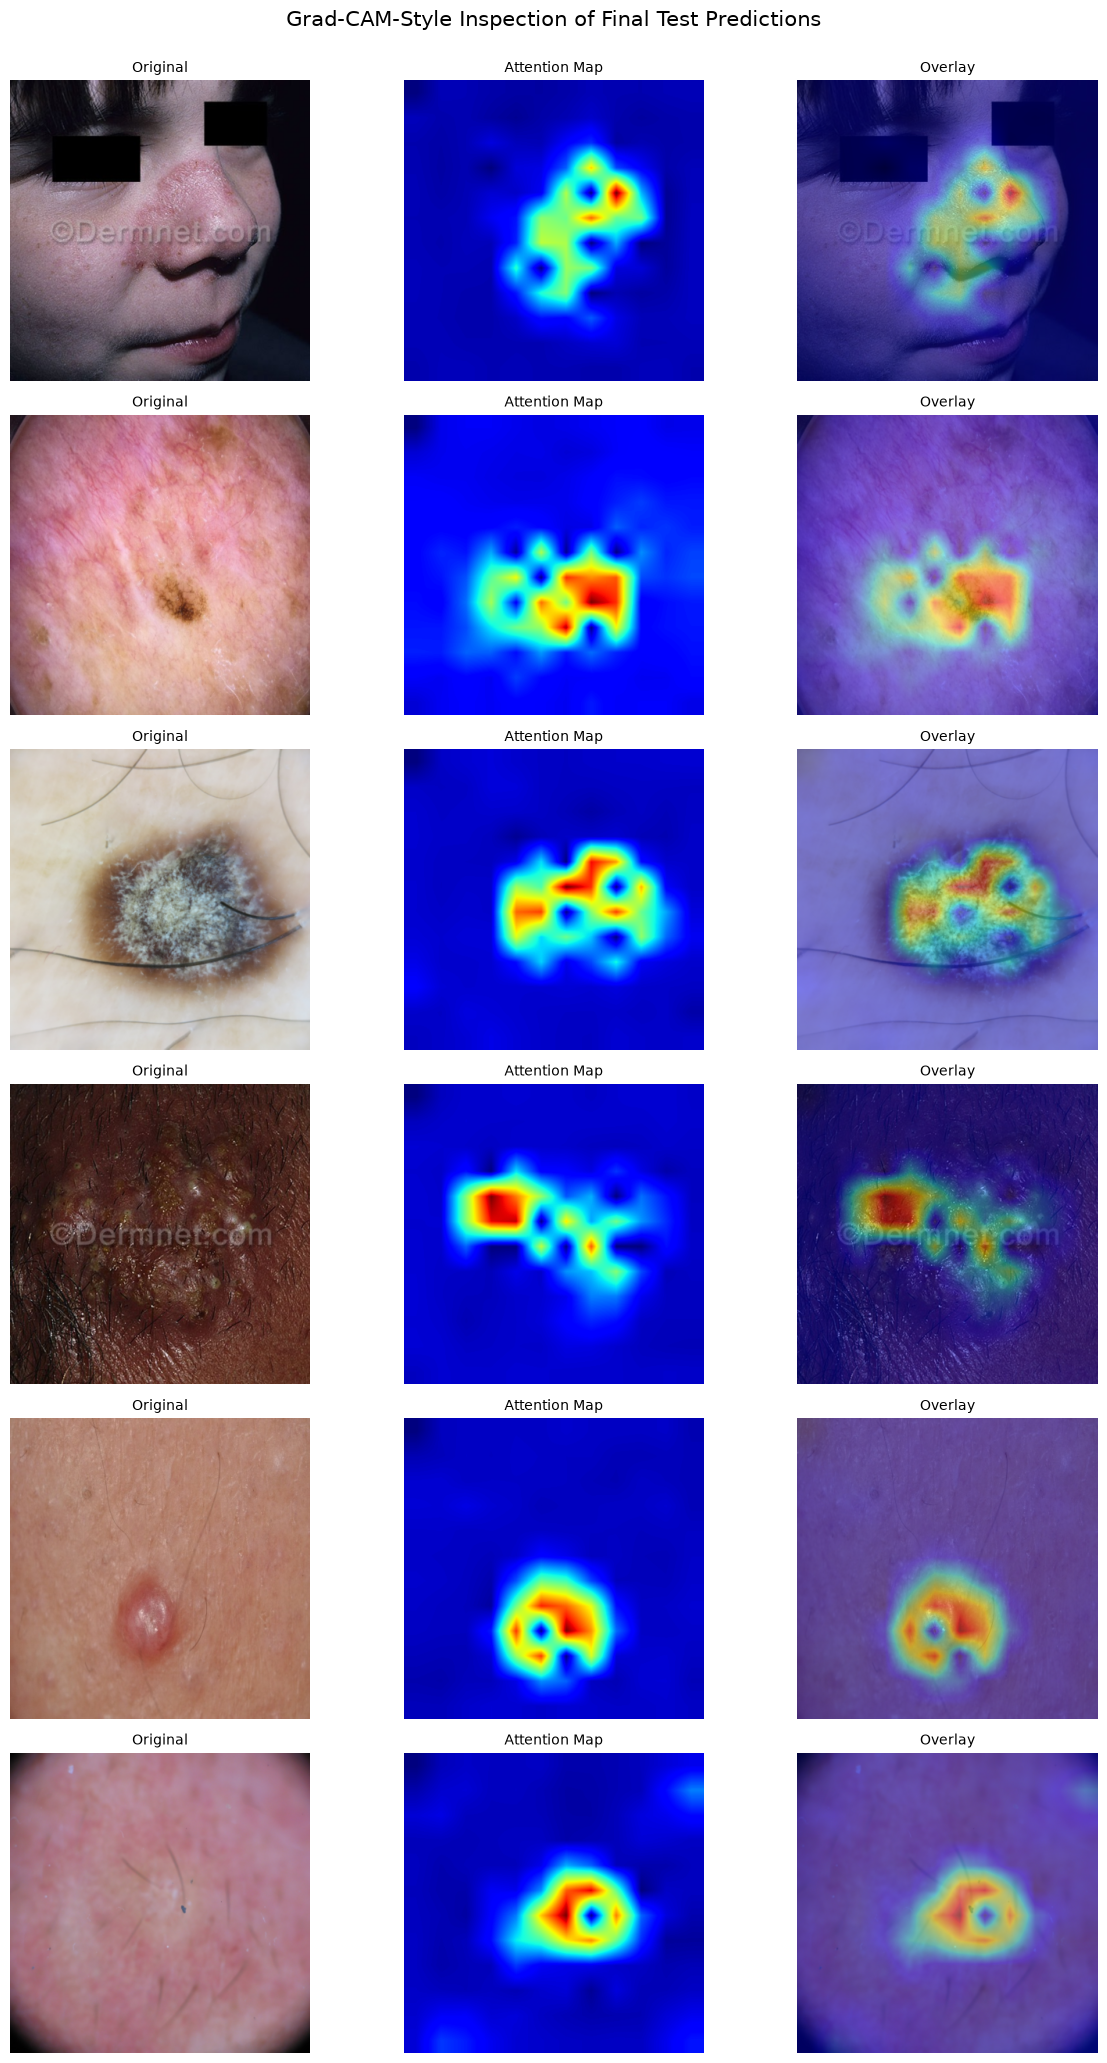

Target feature stage: model.features[7]
Grad-CAM examples: 6
Interpretation must consider lesions together with watermarks, borders, rulers, image edges, and backgrounds; the maps do not establish causality.


In [16]:
def find_final_convolutional_feature_stage(model: nn.Module):
    """Locate the last top-level feature stage that contains a convolution."""
    candidates = []
    for name, module in model.features.named_children():
        if any(isinstance(child, nn.Conv2d) for child in module.modules()):
            candidates.append((name, module))
    if not candidates:
        raise RuntimeError("No convolutional feature stage was found.")
    return candidates[-1]


def select_distinct_class_examples(
    predictions: pd.DataFrame,
    correct: bool,
    count: int,
    random_seed: int,
) -> pd.DataFrame:
    """Select reproducible high-confidence examples from distinct true classes."""
    subset = predictions.loc[predictions["correct"] == correct].copy()
    if subset.empty:
        return subset
    distinct_pool = (
        subset.sort_values(
            ["true_class_id", "confidence", "relative_path"],
            ascending=[True, False, True],
        )
        .drop_duplicates("true_class_id")
    )
    selected = distinct_pool.sample(
        n=min(count, len(distinct_pool)),
        random_state=random_seed,
    )
    if len(selected) < min(count, len(subset)):
        remaining = subset.drop(index=selected.index).sort_values(
            ["confidence", "relative_path"], ascending=[False, True]
        )
        selected = pd.concat(
            [selected, remaining.head(count - len(selected))]
        )
    return selected.head(count).reset_index(drop=True)


def prepare_display_image(relative_path: str) -> np.ndarray:
    """Apply the deterministic resize and crop geometry without normalization."""
    image = load_display_image(relative_path)
    image = TF.resize(
        image,
        test_transform.resize_size,
        interpolation=test_transform.interpolation,
        antialias=True,
    )
    image = TF.center_crop(image, test_transform.crop_size)
    return np.asarray(image, dtype=np.float32) / 255.0


def generate_gradcam(
    model: nn.Module,
    target_layer: nn.Module,
    relative_path: str,
    target_class_id: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Generate a Grad-CAM-style map for one saved model prediction."""
    cache = {}

    def forward_hook(_module, _inputs, output):
        cache["activations"] = output.detach()

    def backward_hook(_module, _grad_input, grad_output):
        cache["gradients"] = grad_output[0].detach()

    forward_handle = target_layer.register_forward_hook(forward_hook)
    backward_handle = target_layer.register_full_backward_hook(backward_hook)
    try:
        image = load_display_image(relative_path)
        input_tensor = test_transform(image).unsqueeze(0).to(DEVICE)
        input_tensor.requires_grad_(True)
        model.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logits = model(input_tensor)
            logits[0, target_class_id].backward()

        activations = cache["activations"]
        gradients = cache["gradients"]
        channel_weights = gradients.mean(dim=(2, 3), keepdim=True)
        heatmap = torch.relu((channel_weights * activations).sum(dim=1, keepdim=True))
        heatmap = F.interpolate(
            heatmap,
            size=(IMAGE_SIZE, IMAGE_SIZE),
            mode="bilinear",
            align_corners=False,
        )[0, 0]
        heatmap -= heatmap.min()
        heatmap /= heatmap.max().clamp_min(1e-8)
        heatmap = heatmap.cpu().numpy()
    finally:
        forward_handle.remove()
        backward_handle.remove()

    original = prepare_display_image(relative_path)
    heatmap_rgb = plt.get_cmap("jet")(heatmap)[..., :3]
    overlay = np.clip(0.55 * original + 0.45 * heatmap_rgb, 0.0, 1.0)
    return original, heatmap, overlay


TARGET_LAYER_NAME, TARGET_LAYER = find_final_convolutional_feature_stage(model)
gradcam_correct = select_distinct_class_examples(
    test_predictions, correct=True, count=3, random_seed=RANDOM_SEED
)
gradcam_incorrect = select_distinct_class_examples(
    test_predictions, correct=False, count=3, random_seed=RANDOM_SEED
)
gradcam_selection = pd.concat(
    [gradcam_correct, gradcam_incorrect], ignore_index=True
)
if gradcam_selection.empty:
    raise RuntimeError("No predictions are available for Grad-CAM analysis.")

gradcam_records = []
for row in gradcam_selection.itertuples(index=False):
    original, heatmap, overlay = generate_gradcam(
        model,
        TARGET_LAYER,
        row.relative_path,
        int(row.predicted_class_id),
    )
    gradcam_records.append(
        {
            "row": row,
            "original": original,
            "heatmap": heatmap,
            "overlay": overlay,
        }
    )

fig, axes = plt.subplots(
    len(gradcam_records),
    3,
    figsize=(12.5, 3.5 * len(gradcam_records)),
    squeeze=False,
)
for row_index, record in enumerate(gradcam_records):
    prediction_row = record["row"]
    outcome = "Correct" if bool(prediction_row.correct) else "Incorrect"
    axes[row_index, 0].imshow(record["original"])
    axes[row_index, 1].imshow(record["heatmap"], cmap="jet", vmin=0, vmax=1)
    axes[row_index, 2].imshow(record["overlay"])
    axes[row_index, 0].set_ylabel(
        f"{outcome}\nTrue: {textwrap.shorten(prediction_row.true_class, 32)}\n"
        f"Pred: {textwrap.shorten(prediction_row.predicted_class, 32)}\n"
        f"Confidence: {prediction_row.confidence:.3f}",
        fontsize=8,
    )
    for column_index, title in enumerate(["Original", "Attention Map", "Overlay"]):
        axes[row_index, column_index].set_title(title, fontsize=10)
        axes[row_index, column_index].axis("off")
fig.suptitle("Grad-CAM-Style Inspection of Final Test Predictions", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, 0.98))
fig.savefig(
    FIGURES_DIR / "08_gradcam_examples.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print(f"Target feature stage: model.features[{TARGET_LAYER_NAME}]")
print(f"Grad-CAM examples: {len(gradcam_records)}")
print(
    "Interpretation must consider lesions together with watermarks, borders, "
    "rulers, image edges, and backgrounds; the maps do not establish causality."
)


## Final Test Results

The following summary is generated directly from the final test calculations.


In [17]:
if most_common_confusion is None:
    most_common_confusion_text = "No misclassifications observed"
else:
    most_common_confusion_text = (
        f"{most_common_confusion['true_class']} predicted as "
        f"{most_common_confusion['predicted_class']} "
        f"({int(most_common_confusion['image_count'])} images)"
    )

final_results_markdown = f"""
- **Selected final model:** {FINAL_MODEL_DISPLAY_NAME}
- **Test accuracy:** {test_metric_values['accuracy']:.4f}
- **Test balanced accuracy:** {test_metric_values['balanced_accuracy']:.4f}
- **Test macro F1:** {test_metric_values['macro_f1']:.4f}
- **Test macro precision:** {test_metric_values['macro_precision']:.4f}
- **Test macro recall:** {test_metric_values['macro_recall']:.4f}
- **Test weighted F1:** {test_metric_values['weighted_f1']:.4f}
- **Strongest class by F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest class by F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most common directed confusion:** {most_common_confusion_text}
"""
display(Markdown(final_results_markdown))



- **Selected final model:** Optimized EfficientNetV2-S
- **Test accuracy:** 0.8896
- **Test balanced accuracy:** 0.8378
- **Test macro F1:** 0.8353
- **Test macro precision:** 0.8345
- **Test macro recall:** 0.8378
- **Test weighted F1:** 0.8900
- **Strongest class by F1:** Melanoma (0.9895)
- **Weakest class by F1:** Atopic Dermatitis (0.6409)
- **Most common directed confusion:** Psoriasis / Lichen Planus / Related Diseases predicted as Eczema (27 images)


### Validation-to-Test Generalization

The interpretation below is descriptive. A small difference between validation and test metrics is not treated as statistically significant without uncertainty estimates or repeated independent evaluation.


In [18]:
macro_f1_difference = float(
    validation_vs_test.loc[
        validation_vs_test["metric"] == "macro_f1", "difference"
    ].iloc[0]
)
accuracy_difference = float(
    validation_vs_test.loc[
        validation_vs_test["metric"] == "accuracy", "difference"
    ].iloc[0]
)
balanced_accuracy_difference = float(
    validation_vs_test.loc[
        validation_vs_test["metric"] == "balanced_accuracy", "difference"
    ].iloc[0]
)

if macro_f1_difference >= -0.03:
    generalization_description = (
        "Test macro F1 is broadly similar to validation macro F1 under a "
        "descriptive 0.03 tolerance."
    )
elif macro_f1_difference >= -0.08:
    generalization_description = (
        "Test macro F1 is moderately lower than validation macro F1."
    )
else:
    generalization_description = (
        "A substantial descriptive validation-to-test macro-F1 gap is present."
    )

generalization_markdown = f"""
{generalization_description}

- Accuracy difference (test − validation): **{accuracy_difference:+.4f}**
- Balanced-accuracy difference (test − validation): **{balanced_accuracy_difference:+.4f}**
- Macro-F1 difference (test − validation): **{macro_f1_difference:+.4f}**

These differences are point estimates and are not claims of statistical significance. No retraining or model revision will be performed in response to the test results.
"""
display(Markdown(generalization_markdown))



Test macro F1 is broadly similar to validation macro F1 under a descriptive 0.03 tolerance.

- Accuracy difference (test − validation): **-0.0053**
- Balanced-accuracy difference (test − validation): **-0.0016**
- Macro-F1 difference (test − validation): **-0.0038**

These differences are point estimates and are not claims of statistical significance. No retraining or model revision will be performed in response to the test results.


### Limitations

- Class imbalance remains present, so aggregate accuracy can obscure weaker minority-class behavior.
- Images originate from heterogeneous acquisition sources and protocols.
- DermNet watermarks, dark dermoscopy borders, rulers, backgrounds, and other source artifacts may support shortcut learning.
- Universal patient identifiers are unavailable; patient-independent splitting cannot be guaranteed for every image.
- Several dataset categories group related but non-identical dermatological conditions.
- Evaluation is limited to one public dataset and does not establish external generalization.
- Softmax scores are not calibrated medical probabilities, and model predictions are not clinical diagnoses.


# Poster-Ready Figures

Poster figures use concise labels, large typography, high-resolution PNG output, and PDF output where practical. Architecture selection figures contain validation results only; final performance figures contain test results only.


## 17. Validation Performance Across Model Architectures

Four baseline architectures and the optimized EfficientNetV2-S are compared using validation accuracy, balanced accuracy, and macro F1. Test results are excluded from this model-selection figure.


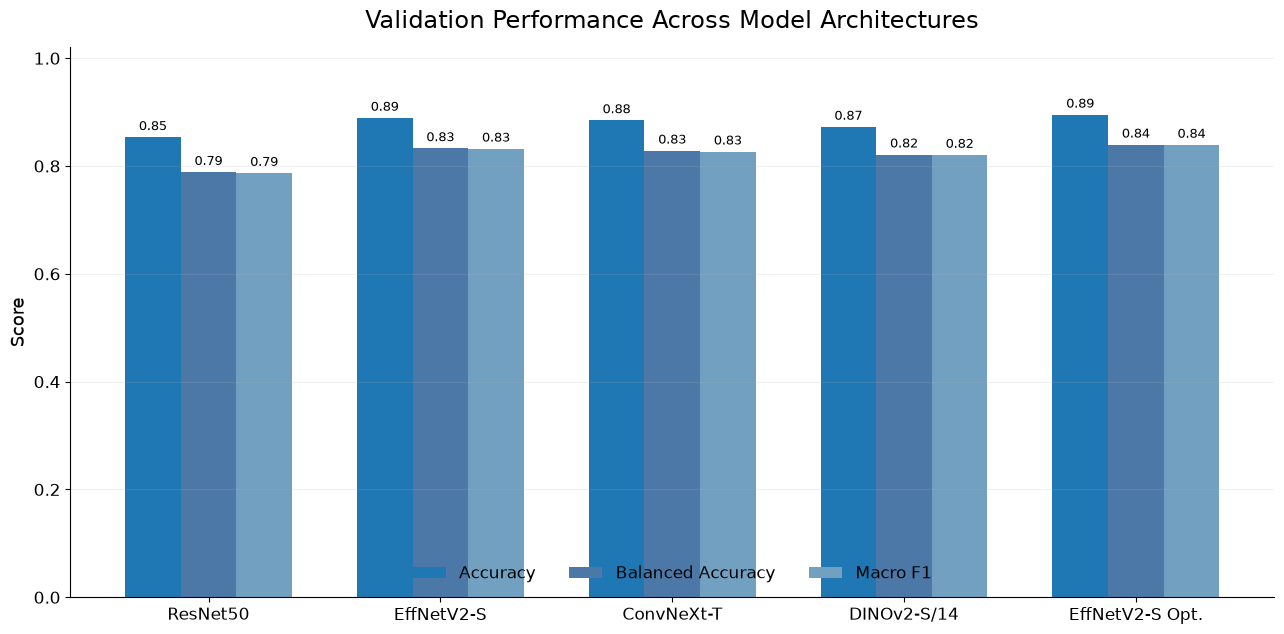

In [19]:
ARCHITECTURE_COMPARISON_PATH = (
    REPORTS_DIR / "06_architecture_baseline_comparison.csv"
)
OPTIMIZED_VALIDATION_METRICS_PATH = (
    REPORTS_DIR / "07_efficientnetv2_optimized_validation_metrics.csv"
)
for required_path in [
    ARCHITECTURE_COMPARISON_PATH,
    OPTIMIZED_VALIDATION_METRICS_PATH,
]:
    if not required_path.is_file():
        raise FileNotFoundError(f"Poster input is missing: {required_path}")

architecture_baselines = pd.read_csv(ARCHITECTURE_COMPARISON_PATH)
optimized_validation_report = pd.read_csv(OPTIMIZED_VALIDATION_METRICS_PATH)
optimized_validation_values = optimized_validation_report.set_index("metric")["value"]
POSTER_METRICS = ["accuracy", "balanced_accuracy", "macro_f1"]

required_architecture_columns = {"architecture", *POSTER_METRICS}
missing_architecture_columns = required_architecture_columns - set(
    architecture_baselines.columns
)
if missing_architecture_columns:
    raise ValueError(
        "The architecture comparison is missing columns: "
        f"{sorted(missing_architecture_columns)}"
    )
missing_optimized_metrics = set(POSTER_METRICS) - set(
    optimized_validation_values.index
)
if missing_optimized_metrics:
    raise ValueError(
        "The optimized validation report is missing metrics: "
        f"{sorted(missing_optimized_metrics)}"
    )

architecture_order = [
    "ResNet50",
    "EfficientNetV2-S",
    "ConvNeXt-Tiny",
    "DINOv2 ViT-S/14",
]
if set(architecture_order) - set(architecture_baselines["architecture"]):
    raise ValueError("The four expected baseline architectures are not all present.")
architecture_validation = (
    architecture_baselines.set_index("architecture")
    .loc[architecture_order, POSTER_METRICS]
    .reset_index()
)
architecture_validation = pd.concat(
    [
        architecture_validation,
        pd.DataFrame(
            [
                {
                    "architecture": "Optimized EfficientNetV2-S",
                    **{
                        metric: float(optimized_validation_values[metric])
                        for metric in POSTER_METRICS
                    },
                }
            ]
        ),
    ],
    ignore_index=True,
)

model_labels = [
    "ResNet50",
    "EffNetV2-S",
    "ConvNeXt-T",
    "DINOv2-S/14",
    "EffNetV2-S Opt.",
]
metric_labels = ["Accuracy", "Balanced Accuracy", "Macro F1"]
metric_colors = ["#1f77b4", "#4c78a8", "#72a0c1"]
x_positions = np.arange(len(model_labels))
bar_width = 0.24

with plt.rc_context({"font.size": 12, "axes.titlesize": 17, "axes.labelsize": 13}):
    fig, ax = plt.subplots(figsize=(13, 6.5))
    for metric_index, (metric, label, color) in enumerate(
        zip(POSTER_METRICS, metric_labels, metric_colors)
    ):
        offsets = (metric_index - 1) * bar_width
        bars = ax.bar(
            x_positions + offsets,
            architecture_validation[metric],
            width=bar_width,
            label=label,
            color=color,
        )
        ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)
    ax.set_title("Validation Performance Across Model Architectures", pad=14)
    ax.set_ylabel("Score")
    ax.set_xticks(x_positions, model_labels)
    ax.set_ylim(0, 1.02)
    ax.legend(ncol=3, frameon=False, loc="lower center")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    fig.tight_layout()
    fig.savefig(
        POSTER_FIGURES_DIR / "model_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "model_comparison.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


## 18. Final Test Performance

This figure reports only the selected final model's test accuracy, balanced accuracy, and macro F1.


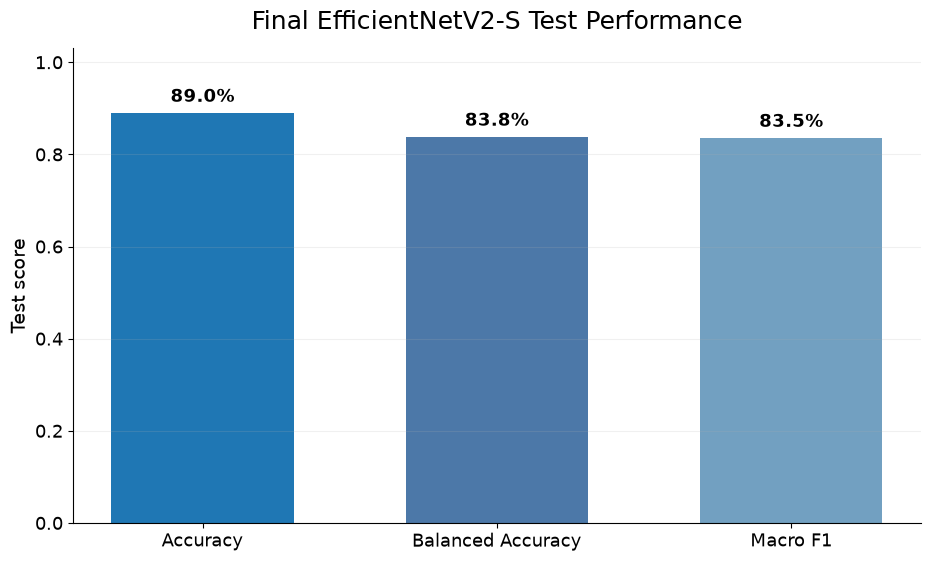

In [20]:
final_test_poster_metrics = pd.DataFrame(
    {
        "metric": ["Accuracy", "Balanced Accuracy", "Macro F1"],
        "value": [
            test_metric_values["accuracy"],
            test_metric_values["balanced_accuracy"],
            test_metric_values["macro_f1"],
        ],
    }
)
final_model_title = (
    "Final EfficientNetV2-S Test Performance"
    if "EfficientNetV2-S" in FINAL_MODEL_DISPLAY_NAME
    else f"Final {FINAL_MODEL_DISPLAY_NAME} Test Performance"
)

with plt.rc_context({"font.size": 13, "axes.titlesize": 18, "axes.labelsize": 14}):
    fig, ax = plt.subplots(figsize=(9.5, 5.8))
    bars = ax.bar(
        final_test_poster_metrics["metric"],
        final_test_poster_metrics["value"],
        color=["#1f77b4", "#4c78a8", "#72a0c1"],
        width=0.62,
    )
    ax.bar_label(
        bars,
        labels=[f"{value:.1%}" for value in final_test_poster_metrics["value"]],
        padding=5,
        fontsize=13,
        fontweight="bold",
    )
    ax.set_title(final_model_title, pad=14)
    ax.set_ylabel("Test score")
    ax.set_ylim(0, 1.03)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    fig.tight_layout()
    fig.savefig(
        POSTER_FIGURES_DIR / "final_test_metrics.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "final_test_metrics.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


## 19. Per-Class Test F1

Display names are shortened for readability without changing the underlying class definitions. Classes are ordered from highest to lowest test F1.


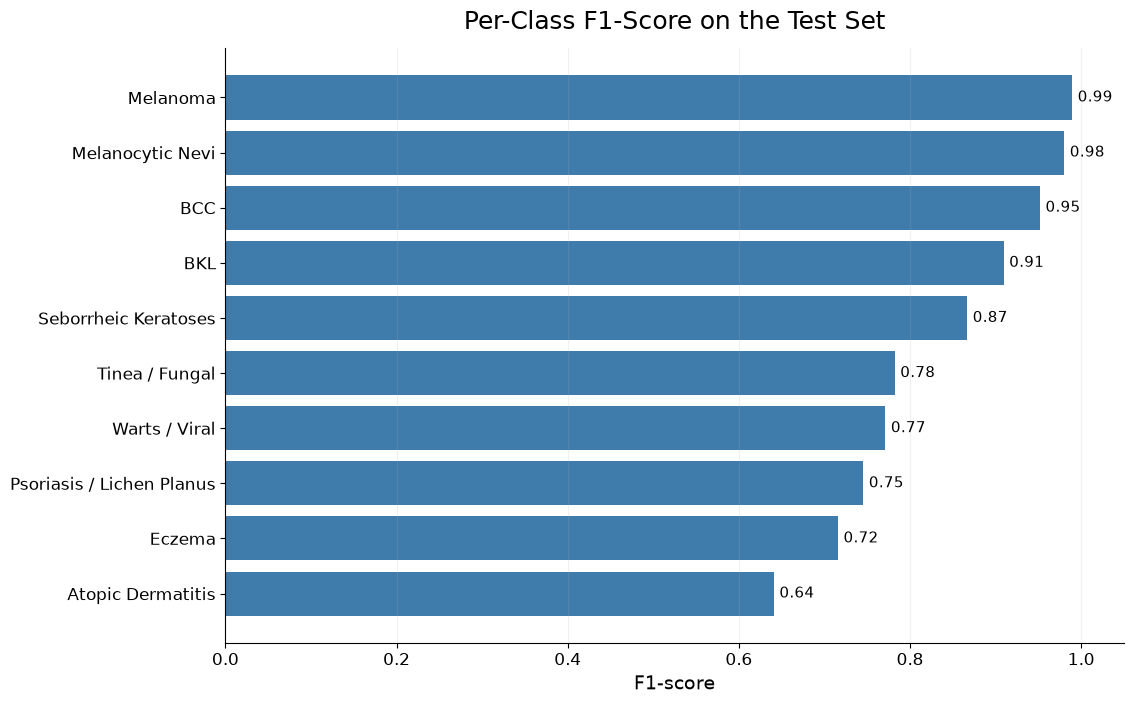

In [21]:
POSTER_CLASS_NAMES = {
    "Eczema": "Eczema",
    "Melanoma": "Melanoma",
    "Atopic Dermatitis": "Atopic Dermatitis",
    "Basal Cell Carcinoma (BCC)": "BCC",
    "Melanocytic Nevi (NV)": "Melanocytic Nevi",
    "Benign Keratosis-like Lesions (BKL)": "BKL",
    "Psoriasis / Lichen Planus / Related Diseases": "Psoriasis / Lichen Planus",
    "Seborrheic Keratoses / Other Benign Tumors": "Seborrheic Keratoses",
    "Tinea / Ringworm / Candidiasis / Other Fungal Infections": "Tinea / Fungal",
    "Warts / Molluscum / Other Viral Infections": "Warts / Viral",
}
if set(test_per_class_metrics["class_name"]) - set(POSTER_CLASS_NAMES):
    raise ValueError("Poster display labels are missing for one or more classes.")

poster_per_class = test_per_class_metrics.copy()
poster_per_class["display_name"] = poster_per_class["class_name"].map(
    POSTER_CLASS_NAMES
)
poster_per_class = poster_per_class.sort_values(
    "f1_score", ascending=True, ignore_index=True
)

with plt.rc_context({"font.size": 12, "axes.titlesize": 18, "axes.labelsize": 14}):
    fig, ax = plt.subplots(figsize=(11.5, 7.2))
    bars = ax.barh(
        poster_per_class["display_name"],
        poster_per_class["f1_score"],
        color="#3f7cac",
    )
    ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=11)
    ax.set_title("Per-Class F1-Score on the Test Set", pad=14)
    ax.set_xlabel("F1-score")
    ax.set_xlim(0, 1.05)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.18)
    fig.tight_layout()
    fig.savefig(
        POSTER_FIGURES_DIR / "per_class_test_f1.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "per_class_test_f1.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


## 20. Normalized Confusion Matrix for the Final Model

The poster matrix uses shortened class names and row percentages to preserve readability.


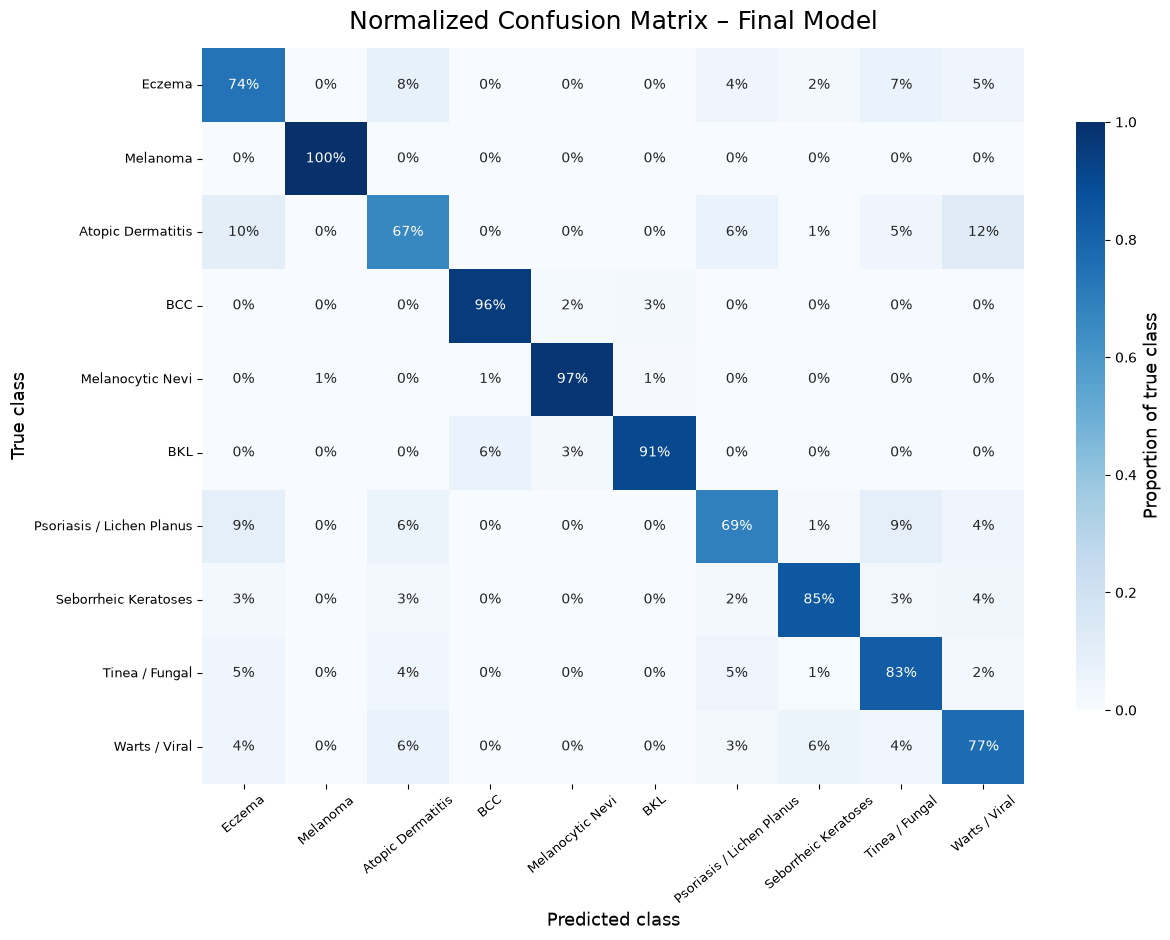

In [22]:
poster_class_labels = [
    POSTER_CLASS_NAMES[CLASS_ID_TO_NAME[int(class_id)]]
    for class_id in class_ids
]
poster_annotations = np.vectorize(lambda value: f"{value:.0%}")(
    normalized_confusion_matrix
)

with plt.rc_context({"font.size": 10, "axes.titlesize": 18, "axes.labelsize": 13}):
    fig, ax = plt.subplots(figsize=(12.5, 9.5))
    sns.heatmap(
        normalized_confusion_matrix,
        annot=poster_annotations,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=poster_class_labels,
        yticklabels=poster_class_labels,
        cbar_kws={"label": "Proportion of true class", "shrink": 0.8},
        ax=ax,
    )
    ax.set_title("Normalized Confusion Matrix – Final Model", pad=14)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(axis="x", rotation=40, labelsize=9)
    ax.tick_params(axis="y", rotation=0, labelsize=9)
    fig.tight_layout()
    fig.savefig(
        POSTER_FIGURES_DIR / "final_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "final_confusion_matrix.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


## 21. Effect of Final Model Optimization

The baseline and optimized EfficientNetV2-S are compared using validation metrics only.


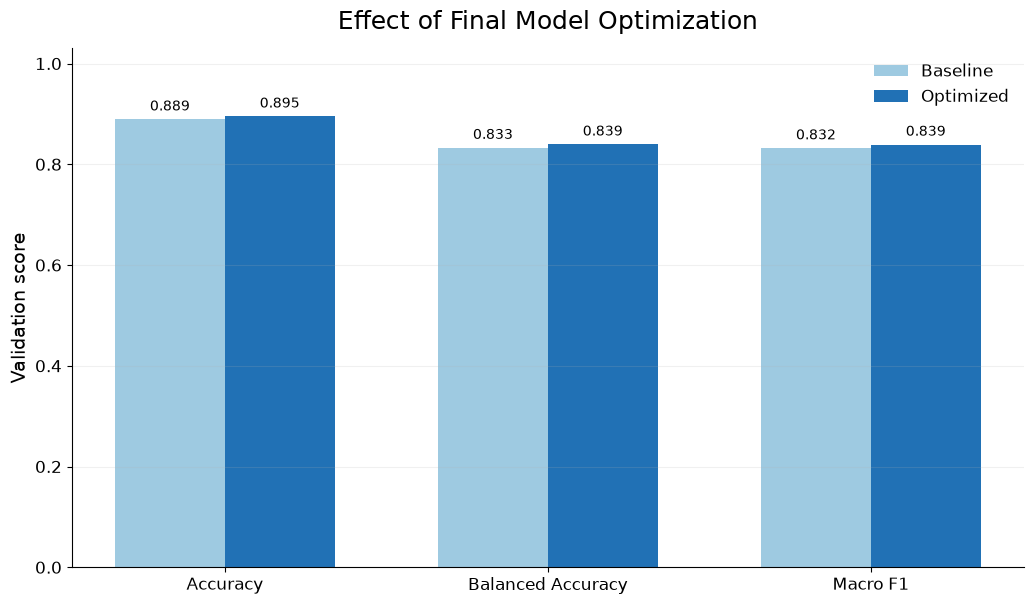

In [23]:
BASELINE_VALIDATION_METRICS_PATH = (
    REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv"
)
if not BASELINE_VALIDATION_METRICS_PATH.is_file():
    raise FileNotFoundError(
        f"Poster input is missing: {BASELINE_VALIDATION_METRICS_PATH}"
    )
baseline_validation_values = (
    pd.read_csv(BASELINE_VALIDATION_METRICS_PATH)
    .set_index("metric")["value"]
)
missing_baseline_metrics = set(POSTER_METRICS) - set(
    baseline_validation_values.index
)
if missing_baseline_metrics:
    raise ValueError(
        "The baseline validation report is missing metrics: "
        f"{sorted(missing_baseline_metrics)}"
    )

baseline_vs_optimized_poster = pd.DataFrame(
    {
        "metric": ["Accuracy", "Balanced Accuracy", "Macro F1"],
        "Baseline": [
            float(baseline_validation_values[metric])
            for metric in POSTER_METRICS
        ],
        "Optimized": [
            float(optimized_validation_values[metric])
            for metric in POSTER_METRICS
        ],
    }
)
x_positions = np.arange(len(baseline_vs_optimized_poster))
bar_width = 0.34

with plt.rc_context({"font.size": 12, "axes.titlesize": 18, "axes.labelsize": 14}):
    fig, ax = plt.subplots(figsize=(10.5, 6.2))
    baseline_bars = ax.bar(
        x_positions - bar_width / 2,
        baseline_vs_optimized_poster["Baseline"],
        width=bar_width,
        label="Baseline",
        color="#9ecae1",
    )
    optimized_bars = ax.bar(
        x_positions + bar_width / 2,
        baseline_vs_optimized_poster["Optimized"],
        width=bar_width,
        label="Optimized",
        color="#2171b5",
    )
    ax.bar_label(baseline_bars, fmt="%.3f", padding=4, fontsize=10)
    ax.bar_label(optimized_bars, fmt="%.3f", padding=4, fontsize=10)
    ax.set_title("Effect of Final Model Optimization", pad=14)
    ax.set_ylabel("Validation score")
    ax.set_xticks(x_positions, baseline_vs_optimized_poster["metric"])
    ax.set_ylim(0, 1.03)
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.18)
    fig.tight_layout()
    fig.savefig(
        POSTER_FIGURES_DIR / "baseline_vs_optimized.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "baseline_vs_optimized.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)


## 22. Optional Poster Grad-CAM Panel

A four-example panel is exported for visual review. It should be included in the poster only if the overlays remain clear at poster scale and are presented as qualitative attention diagnostics rather than evidence of clinical reasoning.


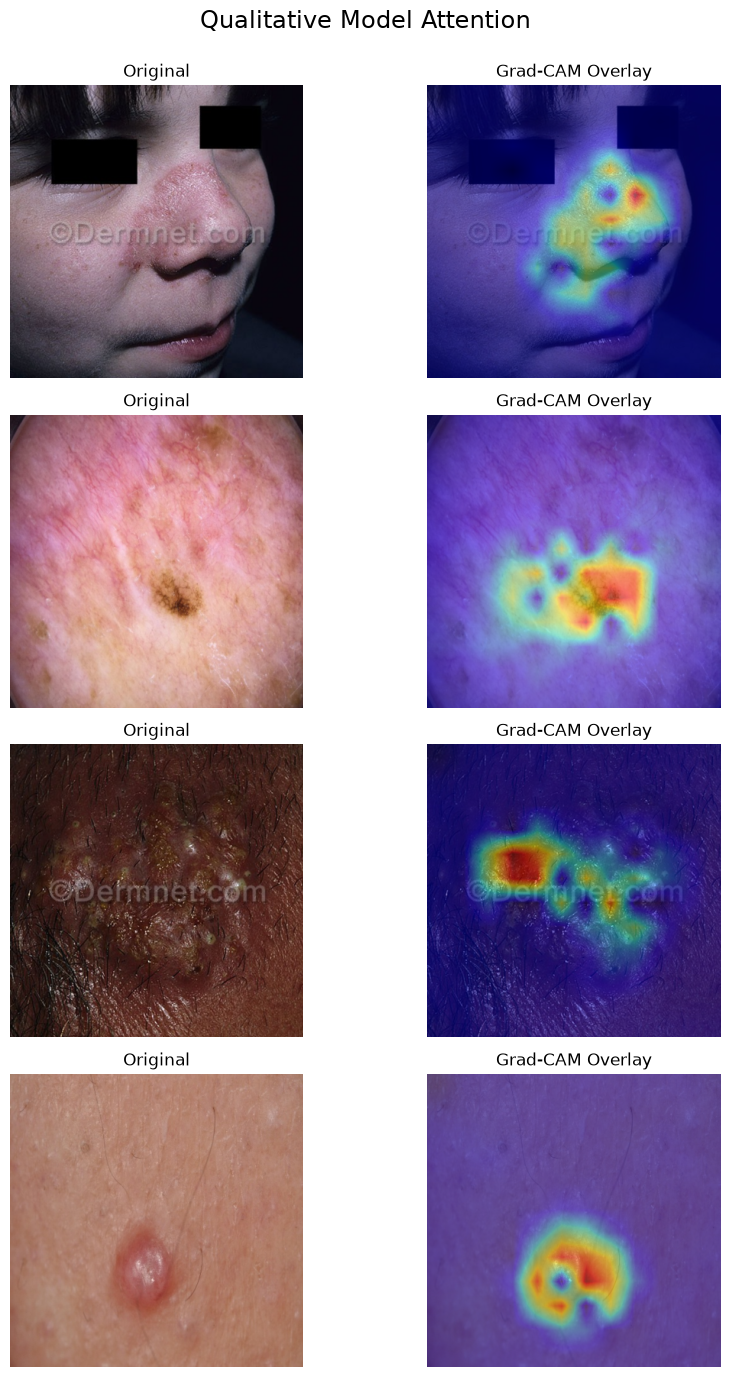

Optional Grad-CAM poster panel saved for visual review.


In [24]:
poster_gradcam_records = []
correct_added = 0
incorrect_added = 0
for record in gradcam_records:
    is_correct = bool(record["row"].correct)
    if is_correct and correct_added < 2:
        poster_gradcam_records.append(record)
        correct_added += 1
    elif not is_correct and incorrect_added < 2:
        poster_gradcam_records.append(record)
        incorrect_added += 1

if poster_gradcam_records:
    fig, axes = plt.subplots(
        len(poster_gradcam_records),
        2,
        figsize=(9.5, 3.5 * len(poster_gradcam_records)),
        squeeze=False,
    )
    for row_index, record in enumerate(poster_gradcam_records):
        prediction_row = record["row"]
        outcome = "Correct" if bool(prediction_row.correct) else "Incorrect"
        axes[row_index, 0].imshow(record["original"])
        axes[row_index, 1].imshow(record["overlay"])
        axes[row_index, 0].set_ylabel(
            f"{outcome}\nTrue: {POSTER_CLASS_NAMES[prediction_row.true_class]}\n"
            f"Pred: {POSTER_CLASS_NAMES[prediction_row.predicted_class]}",
            fontsize=10,
        )
        axes[row_index, 0].set_title("Original", fontsize=12)
        axes[row_index, 1].set_title("Grad-CAM Overlay", fontsize=12)
        for axis in axes[row_index]:
            axis.axis("off")
    fig.suptitle("Qualitative Model Attention", fontsize=17)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(
        POSTER_FIGURES_DIR / "gradcam_panel.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        POSTER_FIGURES_DIR / "gradcam_panel.pdf",
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)
    print("Optional Grad-CAM poster panel saved for visual review.")
else:
    print("No suitable examples were available for the optional Grad-CAM panel.")


## Recommended Figures for the Conference Poster

Only three complementary figures are recommended. The selection below adapts to the observed class-level spread and largest directed confusion rate.


In [25]:
per_class_f1_range = float(
    test_per_class_metrics["f1_score"].max()
    - test_per_class_metrics["f1_score"].min()
)
off_diagonal_normalized = normalized_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_normalized, 0.0)
largest_directed_confusion_rate = float(off_diagonal_normalized.max())

second_figure = (
    "Per-Class F1-Score on the Test Set"
    if per_class_f1_range >= 0.10
    else "Final Test Performance"
)
second_reason = (
    f"The observed per-class F1 range is {per_class_f1_range:.3f}."
    if per_class_f1_range >= 0.10
    else f"The per-class F1 range is limited to {per_class_f1_range:.3f}, so the compact overall summary is clearer."
)
third_figure = "Normalized Confusion Matrix – Final Model"
third_reason = (
    "It displays the direction and magnitude of test errors; the largest "
    f"off-diagonal row proportion is {largest_directed_confusion_rate:.1%}."
)

recommended_figures = pd.DataFrame(
    {
        "priority": [1, 2, 3],
        "figure": [
            "Validation Performance Across Model Architectures",
            second_figure,
            third_figure,
        ],
        "reason": [
            "Summarizes validation-only architecture selection and final optimization.",
            second_reason,
            third_reason,
        ],
    }
)
display(recommended_figures)
print("Do not show all generated figures on the conference poster.")


,priority,figure,reason
0,1,Validation Performance Across Model Architectures,Summarizes validation-only architecture select...
1,2,Per-Class F1-Score on the Test Set,The observed per-class F1 range is 0.349.
2,3,Normalized Confusion Matrix – Final Model,It displays the direction and magnitude of tes...


Do not show all generated figures on the conference poster.


## 23. Reusable Poster and Reporting Tables

The summary CSVs preserve the values required for poster text and a compact validation-versus-test reporting table.


In [26]:
poster_summary = pd.DataFrame(
    [
        {
            "selected_model": FINAL_MODEL_DISPLAY_NAME,
            "validation_accuracy": float(validation_metric_values["accuracy"]),
            "validation_balanced_accuracy": float(
                validation_metric_values["balanced_accuracy"]
            ),
            "validation_macro_f1": float(
                validation_metric_values["macro_f1"]
            ),
            "test_accuracy": test_metric_values["accuracy"],
            "test_balanced_accuracy": test_metric_values["balanced_accuracy"],
            "test_macro_f1": test_metric_values["macro_f1"],
            "test_macro_precision": test_metric_values["macro_precision"],
            "test_macro_recall": test_metric_values["macro_recall"],
            "test_weighted_f1": test_metric_values["weighted_f1"],
        }
    ]
)
poster_summary.to_csv(
    REPORTS_DIR / "08_poster_summary.csv",
    index=False,
    encoding="utf-8",
)

final_validation_test_comparison = pd.DataFrame(
    {
        "Dataset Split": ["Validation", "Test"],
        "Accuracy": [
            float(validation_metric_values["accuracy"]),
            test_metric_values["accuracy"],
        ],
        "Balanced Accuracy": [
            float(validation_metric_values["balanced_accuracy"]),
            test_metric_values["balanced_accuracy"],
        ],
        "Macro F1": [
            float(validation_metric_values["macro_f1"]),
            test_metric_values["macro_f1"],
        ],
    }
)
final_validation_test_comparison.to_csv(
    REPORTS_DIR / "08_final_validation_test_comparison.csv",
    index=False,
    encoding="utf-8",
)

display(poster_summary.style.format(precision=4))
display(final_validation_test_comparison.style.format(precision=4))


,selected_model,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,test_accuracy,test_balanced_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,test_weighted_f1
0,Optimized EfficientNetV2-S,0.8950,0.8394,0.8391,0.8896,0.8378,0.8353,0.8345,0.8378,0.8900


,Dataset Split,Accuracy,Balanced Accuracy,Macro F1
0,Validation,0.8950,0.8394,0.8391
1,Test,0.8896,0.8378,0.8353


## Final Project Summary

The final scientific summary is generated from saved validation reports and the one-time test evaluation.


In [27]:
baseline_best_row = architecture_validation.iloc[
    :-1
].sort_values("macro_f1", ascending=False).iloc[0]
optimized_macro_f1_improvement = float(
    optimized_validation_values["macro_f1"]
    - baseline_validation_values["macro_f1"]
)
if optimized_macro_f1_improvement > 0:
    optimization_statement = (
        "The final optimization improved validation macro F1 by "
        f"{optimized_macro_f1_improvement:+.4f} relative to the EfficientNetV2-S baseline."
    )
else:
    optimization_statement = (
        "The final optimization did not improve validation macro F1 relative "
        f"to the EfficientNetV2-S baseline ({optimized_macro_f1_improvement:+.4f})."
    )

project_summary_markdown = f"""
Four baseline architectures—ResNet50, EfficientNetV2-S, ConvNeXt-Tiny, and DINOv2 ViT-S/14—were evaluated under the fixed validation protocol. **{baseline_best_row['architecture']}** achieved the strongest baseline validation macro F1 ({baseline_best_row['macro_f1']:.4f}). {optimization_statement}

The preselected **{FINAL_MODEL_DISPLAY_NAME}** was evaluated once on {len(test_manifest):,} images from the untouched test subset. Final test accuracy was **{test_metric_values['accuracy']:.4f}**, balanced accuracy was **{test_metric_values['balanced_accuracy']:.4f}**, and macro F1 was **{test_metric_values['macro_f1']:.4f}**. The strongest class by test F1 was **{highest_f1_row['class_name']}** ({highest_f1_row['f1_score']:.4f}); the weakest was **{lowest_f1_row['class_name']}** ({lowest_f1_row['f1_score']:.4f}).

Interpretation remains limited by class imbalance, heterogeneous image sources, possible source-artifact shortcuts, unavailable universal patient identifiers, grouped disease categories, and evaluation on a single public dataset. The outputs are research classifications, not clinical diagnoses.
"""
display(Markdown(project_summary_markdown))



Four baseline architectures—ResNet50, EfficientNetV2-S, ConvNeXt-Tiny, and DINOv2 ViT-S/14—were evaluated under the fixed validation protocol. **EfficientNetV2-S** achieved the strongest baseline validation macro F1 (0.8319). The final optimization improved validation macro F1 by +0.0072 relative to the EfficientNetV2-S baseline.

The preselected **Optimized EfficientNetV2-S** was evaluated once on 3,960 images from the untouched test subset. Final test accuracy was **0.8896**, balanced accuracy was **0.8378**, and macro F1 was **0.8353**. The strongest class by test F1 was **Melanoma** (0.9895); the weakest was **Atopic Dermatitis** (0.6409).

Interpretation remains limited by class imbalance, heterogeneous image sources, possible source-artifact shortcuts, unavailable universal patient identifiers, grouped disease categories, and evaluation on a single public dataset. The outputs are research classifications, not clinical diagnoses.


### Model Development Status

Model training and selection were completed before this notebook. The final test evaluation completes the predefined model-development workflow, and no further tuning should be performed using test results.


In [28]:
print("Model training completed: True")
print("Model selection completed: True")
print("Final test evaluation completed: True")
print("Further tuning using test results permitted: False")
print(f"Final model: {FINAL_MODEL_DISPLAY_NAME}")
print(f"Final checkpoint: {FINAL_CHECKPOINT_PATH}")
print(f"Final test images: {len(test_manifest):,}")
print(f"Final test accuracy: {test_metric_values['accuracy']:.4f}")
print(
    "Final test balanced accuracy: "
    f"{test_metric_values['balanced_accuracy']:.4f}"
)
print(f"Final test macro F1: {test_metric_values['macro_f1']:.4f}")
print("Training performed in this notebook: False")


Model training completed: True
Model selection completed: True
Final test evaluation completed: True
Further tuning using test results permitted: False
Final model: Optimized EfficientNetV2-S
Final checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_optimized_best.pth
Final test images: 3,960
Final test accuracy: 0.8896
Final test balanced accuracy: 0.8378
Final test macro F1: 0.8353
Training performed in this notebook: False
